## Data Cleaning

The cleaning steps from the main notebook are kept together here so the cleaned dataset can be reused by the later notebooks.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

df = pd.read_csv("../data/01_imported_data.csv")
print("Imported data loaded successfully!")
print("Shape:", df.shape)


Imported data loaded successfully!
Shape: (25000, 19)


# 2. Data Cleaning

The raw dataset contains missing values, duplicate records,
inconsistent categorical values, and invalid numerical values.

The following preprocessing steps will be performed:

1. Remove duplicate records
2. Handle missing values
3. Standardize categorical variables
4. Detect and handle invalid numerical values
5. Detect and handle outliers

In [2]:
df_clean = df.copy()

print("Copy created successfully.")

Copy created successfully.


In [3]:
print("Duplicate rows before cleaning:", df_clean.duplicated().sum())

Duplicate rows before cleaning: 300


In [4]:
df_clean = df_clean.drop_duplicates()

print("Duplicate rows after cleaning:", df_clean.duplicated().sum())
print("New dataset shape:", df_clean.shape)

Duplicate rows after cleaning: 0
New dataset shape: (24700, 19)


In [5]:
print(df_clean["employment_type"].value_counts(dropna=False))

employment_type
Salaried           11614
Self-employed       4870
Business            4039
Contract            2471
Unemployed          1190
NaN                  296
salaried              35
 Salaried             31
SALARIED              26
 Self-employed        23
BUSINESS              19
SELF-EMPLOYED         14
self-employed         13
business              11
CONTRACT              10
 Business             10
contract               9
unemployed             5
 Contract              5
 Unemployed            5
UNEMPLOYED             4
Name: count, dtype: int64


In [6]:
print(df_clean["loan_purpose"].value_counts(dropna=False))

loan_purpose
Personal       6914
Home           5443
Vehicle        5368
Business       3586
Education      2922
NaN             247
 Home            23
 Personal        23
HOME             20
home             20
PERSONAL         19
vehicle          17
personal         15
business         14
BUSINESS         13
VEHICLE          13
 Vehicle         13
 Business         9
EDUCATION         8
education         7
 Education        6
Name: count, dtype: int64


In [7]:
df_clean["employment_type"] = (
    df_clean["employment_type"]
    .astype("string")
    .str.strip()
    .str.title()
)

df_clean["loan_purpose"] = (
    df_clean["loan_purpose"]
    .astype("string")
    .str.strip()
    .str.title()
)

In [8]:
print(df_clean["employment_type"].value_counts(dropna=False))

print(df_clean["loan_purpose"].value_counts(dropna=False))

employment_type
Salaried         11706
Self-Employed     4920
Business          4079
Contract          2495
Unemployed        1204
<NA>               296
Name: count, dtype: Int64
loan_purpose
Personal     6971
Home         5506
Vehicle      5411
Business     3622
Education    2943
<NA>          247
Name: count, dtype: Int64


## 2.1 Detecting Invalid Numerical Values

Numerical variables are checked against logical business constraints
before missing values and outliers are handled.

In [9]:
print("Invalid income values:", (df_clean["income"] <= 0).sum())

Invalid income values: 12


In [10]:
print("Invalid credit score values:",
      ((df_clean["credit_score"] < 300) | (df_clean["credit_score"] > 850)).sum())

Invalid credit score values: 25


In [11]:
print("Invalid DTI values:",
      ((df_clean["debt_to_income"] < 0) | (df_clean["debt_to_income"] > 1)).sum())

Invalid DTI values: 18


In [12]:
print("Invalid payment delay values:",
      (df_clean["payment_delays"] < 0).sum())

Invalid payment delay values: 8


In [13]:
print("Invalid previous default values:",
      (df_clean["previous_defaults"] < 0).sum())

Invalid previous default values: 4


In [14]:
print("Invalid employment years:",
      (df_clean["employment_years"] < 0).sum())

Invalid employment years: 6


In [15]:
print("Invalid contact success rates:",
      ((df_clean["contact_success_rate"] < 0) |
       (df_clean["contact_success_rate"] > 1)).sum())

Invalid contact success rates: 20


In [16]:
df_clean["age"].describe()

df_clean["loan_amount"].describe()

df_clean["interest_rate"].describe()

df_clean["payment_delays"].describe()

df_clean["collateral_value"].describe()

df_clean["contact_success_rate"].describe()

count    24330.000000
mean         0.464980
std          0.164096
min         -0.200000
25%          0.363000
50%          0.476000
75%          0.578000
max          1.500000
Name: contact_success_rate, dtype: float64

In [17]:
df_clean.loc[
    (df_clean["contact_success_rate"] < 0) |
    (df_clean["contact_success_rate"] > 1),
    "contact_success_rate"
] = np.nan

In [18]:
df_clean["contact_success_rate"].describe()

count    24310.000000
mean         0.464507
std          0.162316
min          0.000000
25%          0.363000
50%          0.476000
75%          0.578000
max          0.990000
Name: contact_success_rate, dtype: float64

In [19]:
df_clean["contact_success_rate"].isnull().sum()

np.int64(390)

In [20]:
df_clean["age"].describe()

df_clean["loan_amount"].describe()

df_clean["interest_rate"].describe()

df_clean["payment_delays"].describe()

count    24330.000000
mean         2.126963
std          2.330274
min         -2.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         40.000000
Name: payment_delays, dtype: float64

In [21]:
df_clean.loc[
    df_clean["employment_years"] < 0,
    "employment_years"
] = np.nan

In [22]:
print("Missing employment years:", df_clean["employment_years"].isnull().sum())
print("Minimum employment years:", df_clean["employment_years"].min())

Missing employment years: 6
Minimum employment years: 0.0


In [23]:
df_clean["existing_loans"].describe()

count    24700.00000
mean         1.38085
std          1.24341
min         -2.00000
25%          0.00000
50%          1.00000
75%          2.00000
max         20.00000
Name: existing_loans, dtype: float64

In [24]:
df_clean.loc[
    df_clean["existing_loans"] < 0,
    "existing_loans"
] = np.nan

In [25]:
print("Missing existing loans:", df_clean["existing_loans"].isnull().sum())
print("Minimum existing loans:", df_clean["existing_loans"].min())

Missing existing loans: 5
Minimum existing loans: 0.0


In [26]:
df_clean["previous_defaults"].describe()

count    24404.000000
mean         0.845476
std          1.084215
min         -1.000000
25%          0.000000
50%          1.000000
75%          1.000000
max         12.000000
Name: previous_defaults, dtype: float64

In [27]:
df_clean.loc[
    df_clean["previous_defaults"] < 0,
    "previous_defaults"
] = np.nan

In [28]:
print("Missing previous defaults:", df_clean["previous_defaults"].isnull().sum())
print("Minimum previous defaults:", df_clean["previous_defaults"].min())

Missing previous defaults: 300
Minimum previous defaults: 0.0


In [29]:
df_clean["age"].describe()

count    24700.000000
mean        37.115506
std          8.738342
min         17.000000
25%         31.000000
50%         37.000000
75%         43.000000
max         85.000000
Name: age, dtype: float64

In [30]:
df_clean.loc[
    (df_clean["age"] < 18) | (df_clean["age"] > 70),
    "age"
] = np.nan

In [31]:
print("Missing/invalid ages:", df_clean["age"].isnull().sum())
print("Minimum age:", df_clean["age"].min())
print("Maximum age:", df_clean["age"].max())

Missing/invalid ages: 22
Minimum age: 19.0
Maximum age: 65.0


In [32]:
df_clean["loan_amount"].describe()

count    2.445300e+04
mean     5.319611e+05
std      6.364520e+05
min     -1.000000e+04
25%      2.750000e+05
50%      4.300000e+05
75%      6.650000e+05
max      2.500000e+07
Name: loan_amount, dtype: float64

In [33]:
df_clean.loc[
    df_clean["loan_amount"] <= 0,
    "loan_amount"
] = np.nan

In [34]:
print("Missing/invalid loan amounts:", df_clean["loan_amount"].isnull().sum())
print("Minimum loan amount:", df_clean["loan_amount"].min())

Missing/invalid loan amounts: 256
Minimum loan amount: 50000.0


In [35]:
df_clean["interest_rate"].describe()

count    24700.000000
mean         8.980417
std          1.397144
min          0.500000
25%          8.130000
50%          8.940000
75%          9.790000
max         45.000000
Name: interest_rate, dtype: float64

In [36]:
df_clean.loc[
    (df_clean["interest_rate"] < 3) |
    (df_clean["interest_rate"] > 20),
    "interest_rate"
] = np.nan

In [37]:
print("Missing/invalid interest rates:", df_clean["interest_rate"].isnull().sum())
print("Minimum interest rate:", df_clean["interest_rate"].min())
print("Maximum interest rate:", df_clean["interest_rate"].max())

Missing/invalid interest rates: 25
Minimum interest rate: 6.5
Maximum interest rate: 14.0


In [38]:
df_clean.isnull().sum()

customer_id               0
customer_name             0
loan_id                   0
age                      22
income                  444
employment_type         296
credit_score            369
loan_amount             256
loan_term_months          0
interest_rate            25
debt_to_income          443
existing_loans            5
previous_defaults       300
payment_delays          370
employment_years          6
collateral_value        295
loan_purpose            247
contact_success_rate    390
loan_recovered            0
dtype: int64

In [39]:
numeric_columns = [
    "age",
    "income",
    "credit_score",
    "loan_amount",
    "loan_term_months",
    "interest_rate",
    "debt_to_income",
    "existing_loans",
    "previous_defaults",
    "payment_delays",
    "employment_years",
    "collateral_value",
    "contact_success_rate"
]

In [40]:
for column in numeric_columns:
    df_clean[column] = df_clean[column].fillna(
        df_clean[column].median()
    )

In [41]:
categorical_columns = [
    "employment_type",
    "loan_purpose"
]

for column in categorical_columns:
    df_clean[column] = df_clean[column].fillna(
        df_clean[column].mode()[0]
    )

In [42]:
df_clean.isnull().sum()

customer_id             0
customer_name           0
loan_id                 0
age                     0
income                  0
employment_type         0
credit_score            0
loan_amount             0
loan_term_months        0
interest_rate           0
debt_to_income          0
existing_loans          0
previous_defaults       0
payment_delays          0
employment_years        0
collateral_value        0
loan_purpose            0
contact_success_rate    0
loan_recovered          0
dtype: int64

In [43]:
print("Total missing values:", df_clean.isnull().sum().sum())

Total missing values: 0


In [44]:
print("Employment Type:")
print(df_clean["employment_type"].value_counts())

print("\nLoan Purpose:")
print(df_clean["loan_purpose"].value_counts())

Employment Type:
employment_type
Salaried         12002
Self-Employed     4920
Business          4079
Contract          2495
Unemployed        1204
Name: count, dtype: Int64

Loan Purpose:
loan_purpose
Personal     7218
Home         5506
Vehicle      5411
Business     3622
Education    2943
Name: count, dtype: Int64


In [45]:
print(df_clean["loan_recovered"].value_counts())

loan_recovered
1    16055
0     8645
Name: count, dtype: int64


In [46]:
print(df_clean["loan_recovered"].value_counts(normalize=True) * 100)

loan_recovered
1    65.0
0    35.0
Name: proportion, dtype: float64


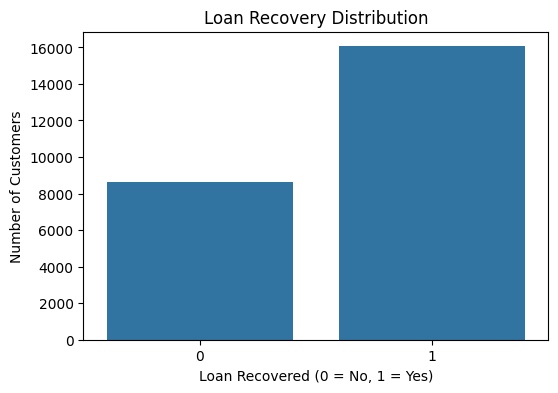

In [47]:
plt.figure(figsize=(6, 4))

sns.countplot(x="loan_recovered", data=df_clean)

plt.title("Loan Recovery Distribution")
plt.xlabel("Loan Recovered (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

plt.show()

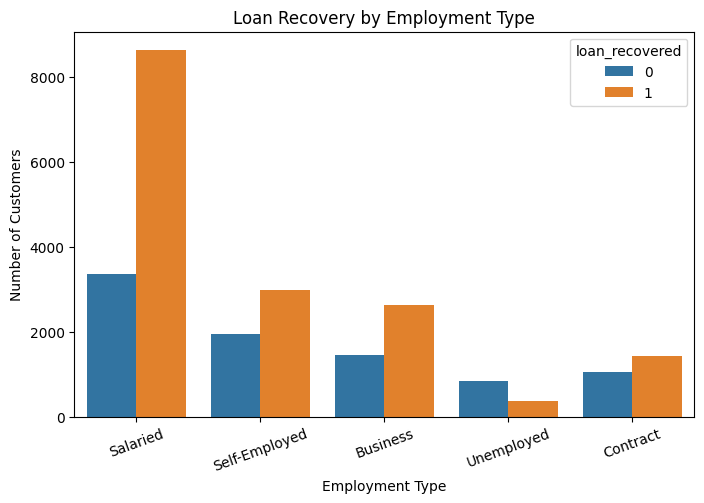

In [48]:
plt.figure(figsize=(8, 5))

sns.countplot(
    x="employment_type",
    hue="loan_recovered",
    data=df_clean
)

plt.title("Loan Recovery by Employment Type")
plt.xlabel("Employment Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)

plt.show()

In [49]:
recovery_by_employment = pd.crosstab(
    df_clean["employment_type"],
    df_clean["loan_recovered"],
    normalize="index"
) * 100

recovery_by_employment

loan_recovered,0,1
employment_type,,
Business,35.351802,64.648198
Contract,42.444890,57.555110
Salaried,28.020330,71.979670
Self-Employed,39.329268,60.670732
Unemployed,70.265781,29.734219


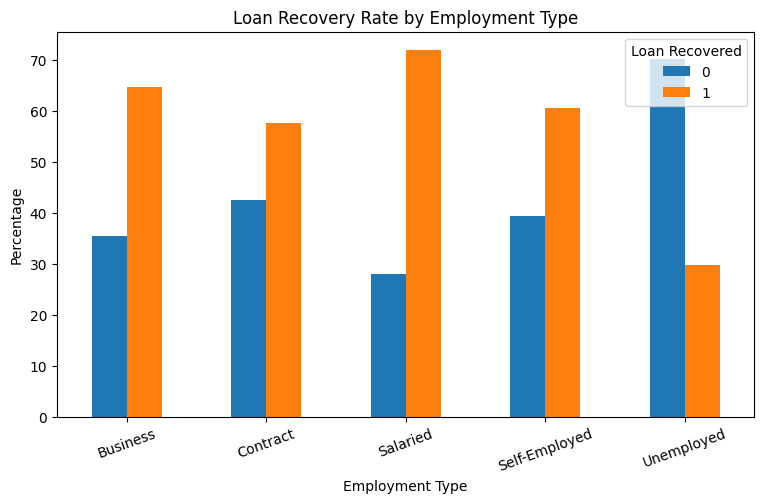

In [50]:
recovery_by_employment.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Loan Recovery Rate by Employment Type")
plt.xlabel("Employment Type")
plt.ylabel("Percentage")
plt.xticks(rotation=20)
plt.legend(title="Loan Recovered")

plt.show()

In [51]:
recovery_by_purpose = pd.crosstab(
    df_clean["loan_purpose"],
    df_clean["loan_recovered"],
    normalize="index"
) * 100

recovery_by_purpose

loan_recovered,0,1
loan_purpose,,
Business,33.903920,66.096080
Education,35.134217,64.865783
Home,36.451144,63.548856
Personal,35.743973,64.256027
Vehicle,33.191647,66.808353


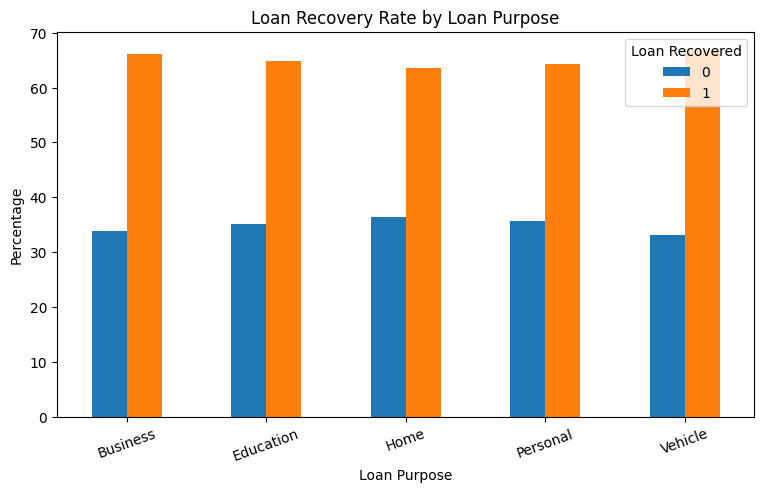

In [52]:
recovery_by_purpose.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Loan Recovery Rate by Loan Purpose")
plt.xlabel("Loan Purpose")
plt.ylabel("Percentage")
plt.xticks(rotation=20)
plt.legend(title="Loan Recovered")

plt.show()

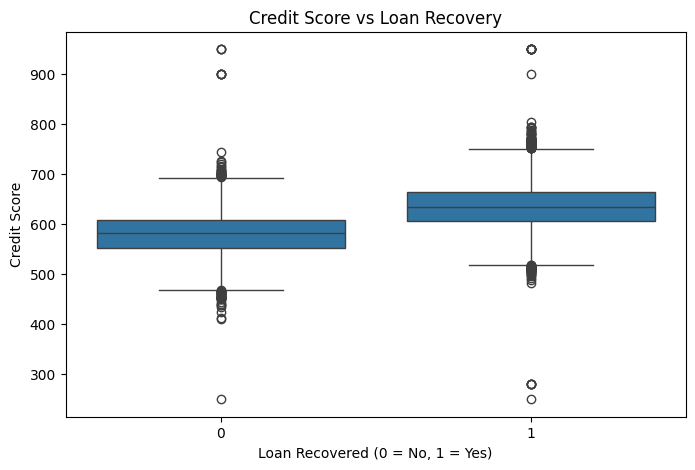

In [53]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x="loan_recovered",
    y="credit_score",
    data=df_clean
)

plt.title("Credit Score vs Loan Recovery")
plt.xlabel("Loan Recovered (0 = No, 1 = Yes)")
plt.ylabel("Credit Score")

plt.show()

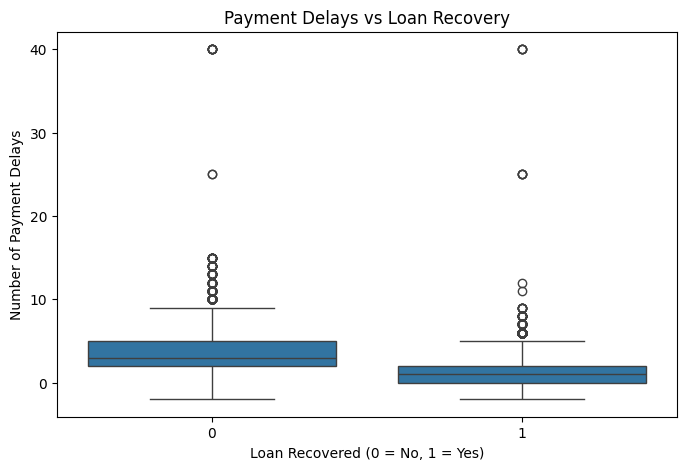

In [54]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x="loan_recovered",
    y="payment_delays",
    data=df_clean
)

plt.title("Payment Delays vs Loan Recovery")
plt.xlabel("Loan Recovered (0 = No, 1 = Yes)")
plt.ylabel("Number of Payment Delays")

plt.show()

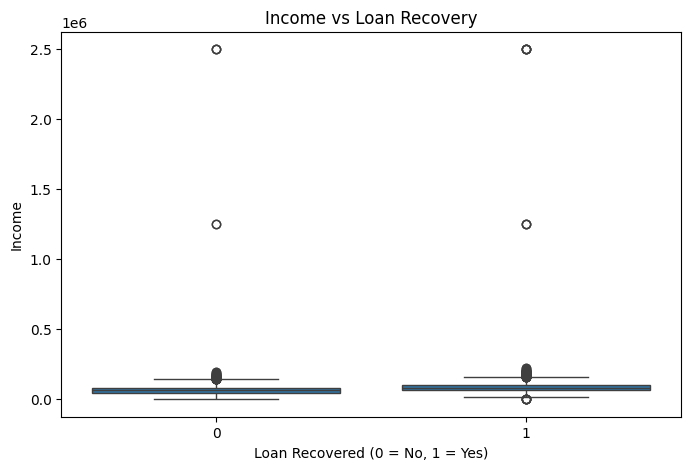

In [55]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x="loan_recovered",
    y="income",
    data=df_clean
)

plt.title("Income vs Loan Recovery")
plt.xlabel("Loan Recovered (0 = No, 1 = Yes)")
plt.ylabel("Income")

plt.show()

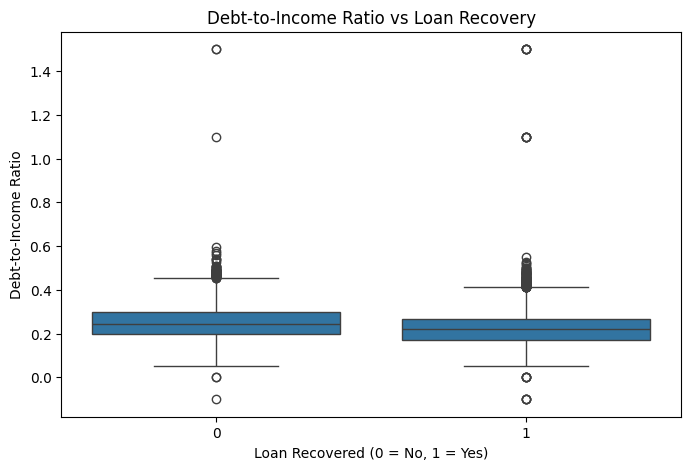

In [56]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x="loan_recovered",
    y="debt_to_income",
    data=df_clean
)

plt.title("Debt-to-Income Ratio vs Loan Recovery")
plt.xlabel("Loan Recovered (0 = No, 1 = Yes)")
plt.ylabel("Debt-to-Income Ratio")

plt.show()

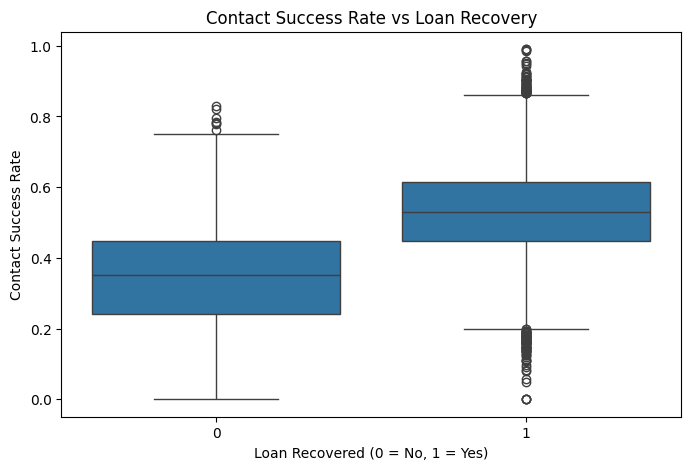

In [57]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x="loan_recovered",
    y="contact_success_rate",
    data=df_clean
)

plt.title("Contact Success Rate vs Loan Recovery")
plt.xlabel("Loan Recovered (0 = No, 1 = Yes)")
plt.ylabel("Contact Success Rate")

plt.show()

## Outlier Detection Using IQR

In [58]:
numeric_columns = [
    "age",
    "income",
    "credit_score",
    "loan_amount",
    "loan_term_months",
    "interest_rate",
    "debt_to_income",
    "existing_loans",
    "previous_defaults",
    "payment_delays",
    "employment_years",
    "collateral_value",
    "contact_success_rate"
]

for column in numeric_columns:
    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df_clean[
        (df_clean[column] < lower_bound) |
        (df_clean[column] > upper_bound)
    ]
    
    print(column, "→", len(outliers), "outliers")

age → 74 outliers
income → 213 outliers
credit_score → 234 outliers
loan_amount → 1216 outliers
loan_term_months → 0 outliers
interest_rate → 79 outliers
debt_to_income → 257 outliers
existing_loans → 85 outliers
previous_defaults → 1920 outliers
payment_delays → 1131 outliers
employment_years → 394 outliers
collateral_value → 1308 outliers
contact_success_rate → 35 outliers


## Outlier Treatment Using IQR Capping

In [59]:
outlier_columns = [
    "income",
    "loan_amount",
    "interest_rate",
    "debt_to_income",
    "collateral_value"
]

for column in outlier_columns:
    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    df_clean[column] = df_clean[column].clip(
        lower_bound,
        upper_bound
    )

print("Outlier capping completed.")

Outlier capping completed.


In [60]:
df_clean[outlier_columns].describe()

,income,loan_amount,interest_rate,debt_to_income,collateral_value
count,24700.000000,2.470000e+04,24700.000000,24700.000000,2.470000e+04
mean,72800.172065,5.032617e+05,8.966242,0.231747,3.435990e+05
std,30103.423600,3.037971e+05,1.196345,0.074716,3.676555e+05
min,-5000.000000,5.000000e+04,6.500000,0.031500,-5.000000e+04
25%,51000.000000,2.750000e+05,8.130000,0.180000,4.500000e+04
50%,71500.000000,4.300000e+05,8.940000,0.229000,2.100000e+05
75%,92500.000000,6.600000e+05,9.790000,0.279000,5.250000e+05
max,154750.000000,1.237500e+06,12.280000,0.427500,1.245000e+06


In [61]:
print("Rows:", df_clean.shape[0])
print("Columns:", df_clean.shape[1])
print("Missing values:", df_clean.isnull().sum().sum())

Rows: 24700
Columns: 19
Missing values: 0


In [62]:
df_clean.loc[
    df_clean["income"] <= 0,
    "income"
] = np.nan

In [63]:
df_clean.loc[
    df_clean["collateral_value"] < 0,
    "collateral_value"
] = np.nan

In [64]:
df_clean.loc[
    (df_clean["credit_score"] < 300) |
    (df_clean["credit_score"] > 850),
    "credit_score"
] = np.nan

In [65]:
columns_to_impute = [
    "income",
    "collateral_value",
    "credit_score"
]

for column in columns_to_impute:
    df_clean[column] = df_clean[column].fillna(
        df_clean[column].median()
    )

In [66]:
print("Missing values:", df_clean.isnull().sum().sum())

print("Minimum income:", df_clean["income"].min())
print("Minimum collateral:", df_clean["collateral_value"].min())
print("Minimum credit score:", df_clean["credit_score"].min())
print("Maximum credit score:", df_clean["credit_score"].max())

Missing values: 0
Minimum income: 10000.0
Minimum collateral: 0.0
Minimum credit score: 410.0
Maximum credit score: 805.0


In [67]:
df_clean.describe()

,age,income,credit_score,loan_amount,loan_term_months,interest_rate,debt_to_income,existing_loans,previous_defaults,payment_delays,employment_years,collateral_value,contact_success_rate,loan_recovered
count,24700.000000,24700.000000,24700.000000,2.470000e+04,24700.000000,24700.000000,24700.000000,24700.000000,24700.000000,24700.000000,24700.000000,2.470000e+04,24700.000000,24700.000000
mean,37.095506,72836.730769,616.145911,5.032617e+05,42.403482,8.966242,0.231747,1.381457,0.847652,2.125061,9.913806,3.437043e+05,0.464688,0.650000
std,8.668583,30056.052227,50.189142,3.037971e+05,17.920969,1.196345,0.074716,1.242491,1.077576,2.312806,5.670899,3.675800e+05,0.161036,0.476979
min,19.000000,10000.000000,410.000000,5.000000e+04,12.000000,6.500000,0.031500,0.000000,0.000000,-2.000000,0.000000,0.000000e+00,0.000000,0.000000
25%,31.000000,51000.000000,583.000000,2.750000e+05,36.000000,8.130000,0.180000,0.000000,0.000000,1.000000,6.000000,4.500000e+04,0.365000,0.000000
50%,37.000000,71500.000000,616.000000,4.300000e+05,36.000000,8.940000,0.229000,1.000000,1.000000,2.000000,10.000000,2.100000e+05,0.476000,1.000000
75%,43.000000,92500.000000,650.000000,6.600000e+05,60.000000,9.790000,0.279000,2.000000,1.000000,3.000000,13.000000,5.250000e+05,0.577000,1.000000
max,65.000000,154750.000000,805.000000,1.237500e+06,84.000000,12.280000,0.427500,20.000000,12.000000,40.000000,50.000000,1.245000e+06,0.990000,1.000000


### Saving the cleaned data

In [68]:

os.makedirs("../data", exist_ok=True)
df_clean.to_csv("../data/02_cleaned_data.csv", index=False)
print("Cleaned data saved successfully!")
print("Final shape:", df_clean.shape)


Cleaned data saved successfully!
Final shape: (24700, 19)
